In [1]:
import os

import numpy as np
import open3d as o3d

import matplotlib.pyplot as plt

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
mesh_database_path = r"E:\2022_tanashi_broccoli\99_broccoli_models"

mesh_db = []
for file in os.listdir(mesh_database_path):
    if ".obj" in file:
        mesh_db.append(os.path.join(mesh_database_path, file))

In [3]:
mesh = o3d.io.read_triangle_mesh(mesh_db[0])

In [4]:
o3d.visualization.draw_geometries([mesh])

In [5]:
dir(mesh)

['HalfEdgeTriangleMesh',
 'Image',
 'LineSet',
 'PointCloud',
 'RGBDImage',
 'TetraMesh',
 'TriangleMesh',
 'Type',
 'Unspecified',
 'VoxelGrid',
 '__add__',
 '__class__',
 '__copy__',
 '__deepcopy__',
 '__delattr__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__gt__',
 '__hash__',
 '__iadd__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 'adjacency_list',
 'clear',
 'cluster_connected_triangles',
 'compute_adjacency_list',
 'compute_convex_hull',
 'compute_triangle_normals',
 'compute_vertex_normals',
 'create_arrow',
 'create_box',
 'create_cone',
 'create_coordinate_frame',
 'create_cylinder',
 'create_from_point_cloud_alpha_shape',
 'create_from_point_cloud_ball_pivoting',
 'create_from_point_cloud_poisson',
 'create_icosahedron',
 'create_moebius',
 'create_octahedron',
 'create_sph

In [5]:
np.asarray(mesh.vertices)

array([[-1.85209997e-02, -2.58620009e-02, -4.84999997e-04],
       [-2.10870001e-02, -2.69690007e-02, -8.39999993e-05],
       [-2.02970002e-02, -2.52000000e-02, -1.28999993e-04],
       ...,
       [ 4.70179990e-02,  1.36280004e-02,  6.13409989e-02],
       [ 4.66450006e-02,  1.54959997e-02,  6.04819991e-02],
       [ 4.58990000e-02,  1.53350001e-02,  6.20459989e-02]])

In [6]:
np.asarray(mesh.vertex_colors)

array([[0.54901999, 0.57254899, 0.278431  ],
       [0.533333  , 0.55294102, 0.25097999],
       [0.52941197, 0.54901999, 0.25490201],
       ...,
       [0.21568599, 0.27058801, 0.129412  ],
       [0.34902   , 0.40784299, 0.235294  ],
       [0.12548999, 0.152941  , 0.047059  ]])

In [7]:
line_set = o3d.geometry.LineSet()

line_set.points = o3d.utility.Vector3dVector(np.array([[0,0,0],[0.1,0,0],[0,0.1,0], [0,0,0.1]]))
line_set.lines = o3d.utility.Vector2iVector([[0,1],[0,2],[0,3]])
line_set.colors = o3d.utility.Vector3dVector(np.array([[1,0,0],[0,1,0],[0,0,1]]))

Mesh顶点转为点云

In [8]:
mesh_pcd = o3d.geometry.PointCloud()
mesh_pcd.points = mesh.vertices
mesh_pcd.colors = mesh.vertex_colors
mesh_pcd.normals = mesh.vertex_normals

In [9]:
# 计算轴对齐边界框
aabb = mesh_pcd.get_axis_aligned_bounding_box()
aabb.color = (1, 0, 0)
 
# 计算定向边界框
obb = mesh_pcd.get_oriented_bounding_box()
obb.color = (0, 0, 0)

In [10]:
ur_set = o3d.geometry.LineSet()

ur_set.points = o3d.utility.Vector3dVector(np.array([[0,0,0], obb.R[:,0], obb.R[:,1], obb.R[:,2]]))
ur_set.lines = o3d.utility.Vector2iVector([[0,1],[0,2],[0,3]])
ur_set.colors = o3d.utility.Vector3dVector(np.array([[1,1,0],[0,1,1],[1,0,1]]))

In [12]:
o3d.visualization.draw_geometries([mesh_pcd, aabb, obb, line_set, ur_set])

![](images/01_bbox2.png)

In [11]:
dir(obb)

['HalfEdgeTriangleMesh',
 'Image',
 'LineSet',
 'PointCloud',
 'R',
 'RGBDImage',
 'TetraMesh',
 'TriangleMesh',
 'Type',
 'Unspecified',
 'VoxelGrid',
 '__class__',
 '__copy__',
 '__deepcopy__',
 '__delattr__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 'center',
 'clear',
 'color',
 'create_from_axis_aligned_bounding_box',
 'create_from_points',
 'dimension',
 'extent',
 'get_axis_aligned_bounding_box',
 'get_box_points',
 'get_center',
 'get_geometry_type',
 'get_max_bound',
 'get_min_bound',
 'get_oriented_bounding_box',
 'get_point_indices_within_bounding_box',
 'get_rotation_matrix_from_axis_angle',
 'get_rotation_matrix_from_quaternion',
 'get_rotation_matrix_from_xyz',
 'get_rotation_matrix_from_xzy',
 'get_rotati

In [10]:
obb

OrientedBoundingBox: center: (-0.00801909, -0.00236161, 0.0428011), extent: 0.16197, 0.116838, 0.116443)

In [11]:
obb.R

array([[ 0.04367782, -0.14087643,  0.98906323],
       [-0.92197856,  0.37560511,  0.09421432],
       [-0.38476978, -0.91601017, -0.11347944]])

In [11]:
rev_R = np.linalg.inv(obb.R)
rev_R

array([[ 0.71279518,  0.69426188,  0.09961662],
       [-0.5983298 ,  0.52780207,  0.60284859],
       [-0.36595694,  0.48931116, -0.79161235]])

In [12]:
mesh_pcd_cor = mesh_pcd.rotate(rev_R, center=obb.center)

In [13]:
obb_cor = obb.rotate(rev_R, center=obb.center)

In [16]:
o3d.visualization.draw_geometries([mesh_pcd_cor, obb, obb_cor, line_set])

![](images/01_rotate_obb.png)

![](images/01_rotate_obb_normals.png)

In [14]:
obb_cor.extent

array([0.14762396, 0.0799633 , 0.08457576])

# projects to axis, find the directions, pick the longest axis (as z axis)

In [15]:
mesh_pcd_cor_xyz = np.asarray(mesh_pcd_cor.points)
mesh_pcd_cor_xyz

array([[-0.0391506 , -0.02614817,  0.05436111],
       [-0.04170824, -0.02495539,  0.05444105],
       [-0.03992146, -0.02452151,  0.05505316],
       ...,
       [ 0.04114058, -0.00724748,  0.00075733],
       [ 0.04208602, -0.00655622,  0.00248786],
       [ 0.0415983 , -0.00525199,  0.001444  ]])

In [16]:
mesh_pcd_cor_xyz[:,0]

array([-0.0391506 , -0.04170824, -0.03992146, ...,  0.04114058,
        0.04208602,  0.0415983 ])

In [17]:
import seaborn as sns

<AxesSubplot:ylabel='Density'>

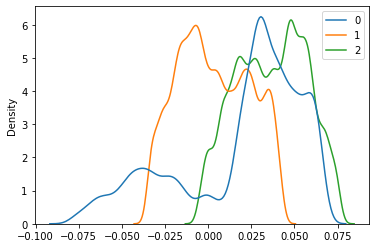

In [18]:
fig, ax = plt.subplots(1,1)
sns.kdeplot(data=mesh_pcd_cor_xyz, ax=ax)

In [19]:
from skimage import filters

In [20]:
val = filters.threshold_otsu(mesh_pcd_cor_xyz[:,0])

In [21]:
val

0.0012075286580995395

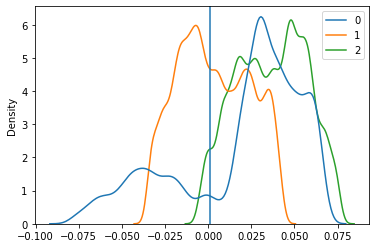

In [22]:
fig, ax = plt.subplots(1,1)
sns.kdeplot(data=mesh_pcd_cor_xyz, ax=ax)
ax.axvline(x=val)
plt.show()

In [23]:
filter_idx = np.where(mesh_pcd_cor_xyz[:,0] >= val)
filter_idx

(array([   33,    34,    35, ..., 64977, 64978, 64979], dtype=int64),)

In [24]:
filter_idx[0]

array([   33,    34,    35, ..., 64977, 64978, 64979], dtype=int64)

In [25]:
cut_pcd_cor = mesh_pcd_cor.select_by_index(filter_idx[0])

In [29]:
o3d.visualization.draw_geometries([cut_pcd_cor])

In [26]:
o3d.visualization.draw_geometries([cut_pcd_cor, obb_cor, line_set])

![](images/01_cut_by_otsu.png)

In [86]:
# 计算定向边界框
cut_obb = cut_pcd_cor.get_oriented_bounding_box()
cut_obb.color = (0, 0, 0)

In [82]:
o3d.visualization.draw_geometries([cut_obb, cut_pcd_cor, line_set])

看起来再来一次就摆正了

![](images/01_rotate_obb2.png)

In [87]:
cut_rev_R = np.linalg.inv(cut_obb.R)
cut_pcd_cor2 = cut_pcd_cor.rotate(cut_rev_R, center=cut_obb.center)
cut_obb_cor = cut_obb.rotate(cut_rev_R, center=cut_obb.center)

In [89]:
o3d.visualization.draw_geometries([cut_obb, cut_pcd_cor2, line_set])

![](images/01_rotate_obb3.png)

In [90]:
# 那继续Otsu切呢？(这次变成了z轴)
cut_pcd_cor_xyz2 = np.asarray(cut_pcd_cor2.points)

<AxesSubplot:ylabel='Density'>

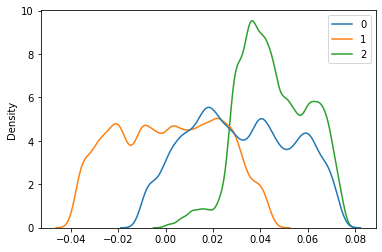

In [92]:
fig, ax = plt.subplots(1,1)
sns.kdeplot(data=cut_pcd_cor_xyz2, ax=ax)

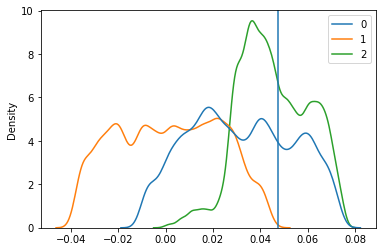

In [93]:
val2 = filters.threshold_otsu(cut_pcd_cor_xyz2[:,2])

fig, ax = plt.subplots(1,1)
sns.kdeplot(data=cut_pcd_cor_xyz2, ax=ax)
ax.axvline(x=val2)
plt.show()

这样就切过了。。。如果把这个rotation应用到一开始的点云上再切呢？

In [94]:
mesh_pcd_cor_full = mesh_pcd_cor.rotate(cut_rev_R, center=obb.center)

In [96]:
o3d.visualization.draw_geometries([cut_obb, mesh_pcd_cor_full, line_set])

![](images/01_full_rotate2.png)

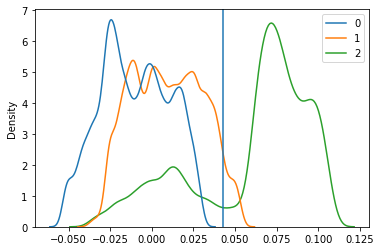

In [97]:
cut_pcd_full_xyz = np.asarray(mesh_pcd_cor_full.points)

val3 = filters.threshold_otsu(cut_pcd_full_xyz[:,2])

fig, ax = plt.subplots(1,1)
sns.kdeplot(data=cut_pcd_full_xyz, ax=ax)
ax.axvline(x=val3)
plt.show()

In [99]:
filter_idx3 = np.where(cut_pcd_full_xyz[:,2] >= val3)
cut_pcd_cor3 = mesh_pcd_cor_full.select_by_index(filter_idx3[0])

In [115]:
filter_idx3 = np.where(cut_pcd_full_xyz[:,2] >= 0.062)
cut_pcd_cor3 = mesh_pcd_cor_full.select_by_index(filter_idx3[0])

In [116]:
o3d.visualization.draw_geometries([cut_pcd_cor3, line_set])

![](images/01_rotate_obb4.png)

用mesh展示：

In [103]:
cut_mesh_final = mesh.select_by_index(filter_idx3[0])

[Open3D WARNING] [SelectByIndex] This mesh contains triangle uvs that are not handled in this function


In [112]:
o3d.visualization.draw_geometries([cut_mesh_final, line_set])

![](images/01_mesh_cut.png)

# 尝试使用机器学习来分割mesh

1. 用Blender分好前景和背景
1. 读入并提取颜色信息与法向量信息
1. 生成分类模型
1. 应用到点云上并显示
1. 测试其他点云的表现形式